<a href="https://colab.research.google.com/github/Jirehcode/Codveda-ML-tasks/blob/main/task-3-house-price-regression/house_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import io
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import make_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from google.colab import drive
from google.colab import files
import os

if not os.path.exists('/content/drive'):
  drive.mount('/content/drive')
  print('Google Drive is mounted')
else:
  print('Google Drive is already mounted')

Google Drive is already mounted


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Codveda Data science Task List/4) house Prediction Data Set.csv', header=None)
df.head()

,0
0,0.00632 18.00 2.310 0 0.5380 6.5750 65...
1,0.02731 0.00 7.070 0 0.4690 6.4210 78...
2,0.02729 0.00 7.070 0 0.4690 7.1850 61...
3,0.03237 0.00 2.180 0 0.4580 6.9980 45...
4,0.06905 0.00 2.180 0 0.4580 7.1470 54...


In [ ]:
# Since the CSV was imported as a single column or with a single string,
# let's make sure we split the columns properly if they are space-separated,
# then extract features (x) and target (y).

# If df has only 1 column, it means the separator was whitespace instead of a comma.
if df.shape[1] == 1:
    # Reload or parse the single column as whitespace separated data
    import io
    # Convert the single column dataframe to string and read it with whitespace delimitation
    raw_txt = df.to_csv(index=False, header=False)
    df = pd.read_csv(io.StringIO(raw_txt), sep=r'\s+', header=None)

# Define features (x) and target (y)
# Typically, the last column is the target (house price), and the rest are features.
x = df.iloc[:, :-1]
y = df.iloc[:, -1]

# Perform train-test split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
x_train.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12
477,15.02340,0.0,18.10,0,0.6140,5.304,97.3,2.1007,24,666.0,20.2,349.48,24.91
15,0.62739,0.0,8.14,0,0.5380,5.834,56.5,4.4986,4,307.0,21.0,395.62,8.47
332,0.03466,35.0,6.06,0,0.4379,6.031,23.3,6.6407,1,304.0,16.9,362.25,7.83
423,7.05042,0.0,18.10,0,0.6140,6.103,85.1,2.0218,24,666.0,20.2,2.52,23.29
19,0.72580,0.0,8.14,0,0.5380,5.727,69.5,3.7965,4,307.0,21.0,390.95,11.28


In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

models = {"Linear Regression": LinearRegression(),
          "Decision Tree": DecisionTreeRegressor(random_state=42,max_depth=5),
          "Random Forest": RandomForestRegressor(random_state=42,n_estimators=100, max_depth=5
          ),
}

results = []

for name, model in models.items():
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({"Model": name, "MSE": mse, "RMSE": rmse, "R2": r2})

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

            Model       MSE     RMSE       R2
Linear Regression 24.291119 4.928602 0.668759
    Decision Tree  8.553907 2.924706 0.883357
    Random Forest  8.909084 2.984809 0.878513


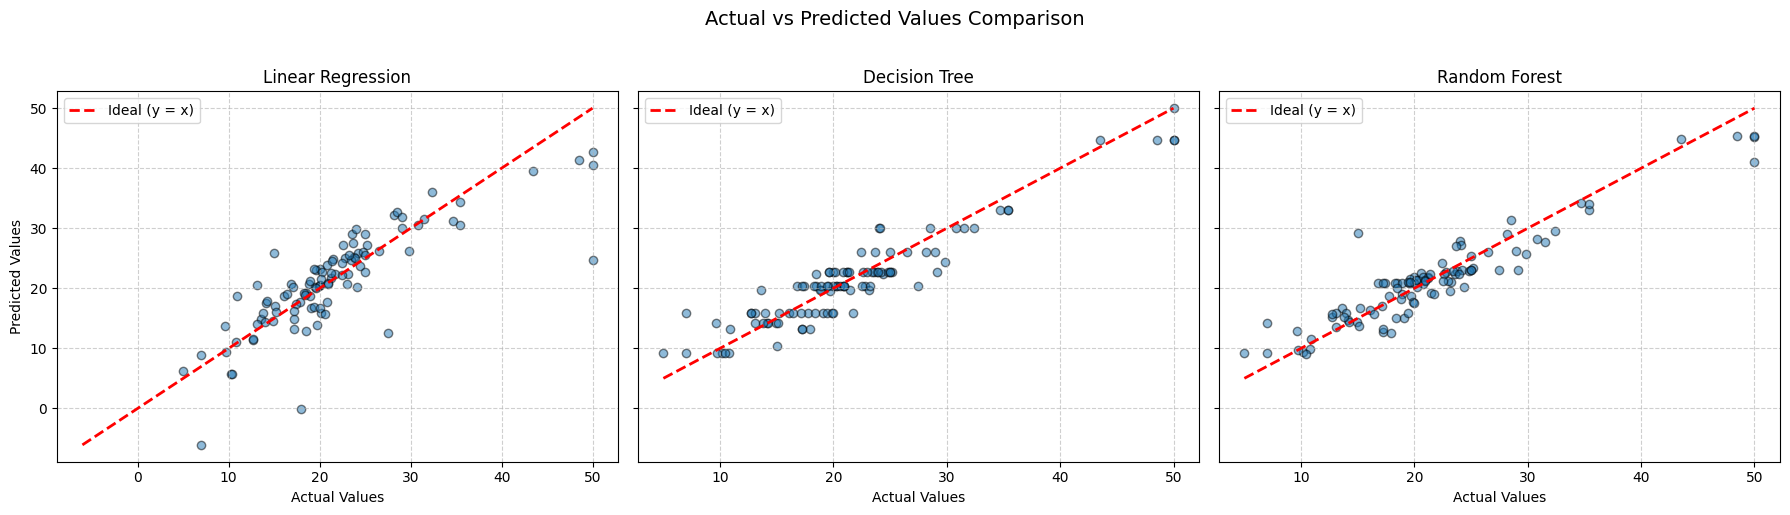

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(x_test)

    ax.scatter(y_test, y_pred, alpha=0.5, edgecolors="k")

    min_val= min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        "r--",
        lw=2,
        label="Ideal (y = x)",
    )
    ax.set_title(f"{name}", fontsize=12)
    ax.set_xlabel("Actual Values")
    if ax == axes[0]:
       ax.set_ylabel("Predicted Values")
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend()

plt.suptitle("Actual vs Predicted Values Comparison", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()